# Thick Sample Ptychography Reconstruction Tutorial 2D

This tutorial demonstrates how to use `thick_ptycho` to Reconstruction a problem with multiple probes via PWE and Multislice.


### 1. Import Libraries: Sample Space and Forward Model


In [8]:
import os
from thick_ptycho.reconstruction.ms_reconstructor import ReconstructorMS
from thick_ptycho.reconstruction.pwe_reconstructor import ReconstructorPWE

from thick_ptycho.simulation.config import SimulationConfig, ProbeConfig
from thick_ptycho.simulation.ptycho_probe import create_ptycho_probes
from thick_ptycho.simulation.scan_frame import Limits
from thick_ptycho.simulation.simulation_space import create_simulation_space

from thick_ptycho.forward_model import PWEIterativeLUSolver
from thick_ptycho.forward_model import MSForwardModelSolver
from thick_ptycho.forward_model import PWEPetscFullPinTSolver

import time
import numpy as np

from scipy.ndimage import zoom

from utils import plot_data, resample_simulation_data

## 2. Load Simulated Data

In [9]:
# File path
#npz_file_path = os.path.join("./data", "padded_simulated_data_six_balls.npz")
npz_file_path = os.path.join("./data", "padded_simulated_data_petsc_5_balls.npz")

# Load the file. MUST use allow_pickle=True since the config was pickled.
loaded_data = np.load(npz_file_path, allow_pickle=True)

# Accessing the contents:

# 1. Load the NumPy arrays directly
exit_waves = loaded_data["exit_waves"]
ref_index = loaded_data["ref_index"]

# 2. Load the sim_config.
loaded_sim_config = loaded_data["sim_config"].item()

print(f"Successfully loaded arrays and config from {npz_file_path}.")

Successfully loaded arrays and config from ./data/padded_simulated_data_petsc_5_balls.npz.


In [10]:
# Reduce Stepsize px
step_size_px = 10
points_per_wavelength = 2
empty_space_px = 100
nz = 50

print(f"Reduce Stepsize px: {loaded_sim_config['step_size_px']} -> {step_size_px}")
# print(
#     f"Points per wavelength: {loaded_sim_config['points_per_wavelength']} -> {points_per_wavelength}"
# )
spatial_limits = Limits(
    x=loaded_sim_config["spatial_limits"]["x"],  # Sample width
    z=loaded_sim_config["spatial_limits"]["z"],  # Sample thickness
    units=loaded_sim_config["spatial_limits"]["units"],
)
probe_config = ProbeConfig(
    type=loaded_sim_config["probe_config"]["type"],
    wave_length=loaded_sim_config["probe_config"][
        "wave_length"
    ],  # meters (0.635 μm). Visible light
    diameter=loaded_sim_config["probe_config"]["diameter"],  # [m]
    focus=loaded_sim_config["probe_config"]["focus"],  # focal length [m]
)
sim_config = SimulationConfig(
    probe_config=probe_config,
    # Spatial discretization
    scan_points=loaded_sim_config["scan_points"],
    step_size_px=step_size_px,
    pad_factor=loaded_sim_config["pad_factor"],
    solve_reduced_domain=loaded_sim_config["solve_reduced_domain"],
    #points_per_wavelength=points_per_wavelength,
    nz=nz,
    spatial_limits=spatial_limits,
    # Refractive index or Transmission Function Constant Surrounding Medium
    medium=loaded_sim_config["medium"],  # 1.0 for free space
    # Logging and results
    results_dir=loaded_sim_config["results_dir"],
    use_logging=loaded_sim_config["use_logging"],
    empty_space_px=empty_space_px,
)
simulation_space = create_simulation_space(sim_config)
simulation_space.summarize()

ptycho_probes = create_ptycho_probes(simulation_space)
print(simulation_space.effective_shape)

2026-01-13 18:31:10,421 - INFO - === Scan Summary ===
2026-01-13 18:31:10,424 - INFO -   Sample space (x-range): 1.500e-04 m
2026-01-13 18:31:10,426 - INFO -   Sample space (z-range): 7.500e-05 m
2026-01-13 18:31:10,429 - INFO -   Sample Pixels:          1501 px
2026-01-13 18:31:10,430 - INFO -   Step size:              10 px
2026-01-13 18:31:10,431 - INFO -   Number of scan points:  60
2026-01-13 18:31:10,433 - INFO -   Steps in z:             50
2026-01-13 18:31:10,437 - INFO -   Solve reduced domain:   910 px
2026-01-13 18:31:10,438 - INFO -   Max Overlap Pixels:     901 px
2026-01-13 18:31:10,440 - INFO -   Probe diameter:         1.000e-05 m
2026-01-13 18:31:10,441 - INFO -   Probe Pixels:           100 px
2026-01-13 18:31:10,443 - INFO -   Max Overlap:            9.000e-06 m
2026-01-13 18:31:10,444 - INFO -   Percentage Overlap:     90.00%



Reduce Stepsize px: 40 -> 10
(1110, 50)


## 3. Reduce Data Dimensionality

In [11]:
resampled_data = resample_simulation_data(
    exit_waves=exit_waves,
    ref_index=ref_index,
    loaded_sim_config=loaded_sim_config,
    simulation_space=simulation_space,
    new_empty_space_px=empty_space_px,
    seed=42
)

Original shape: (60, 7640), Clean width: 3640
Old ratio: 0.5494505494505495, New ratio: 0.10989010989010989


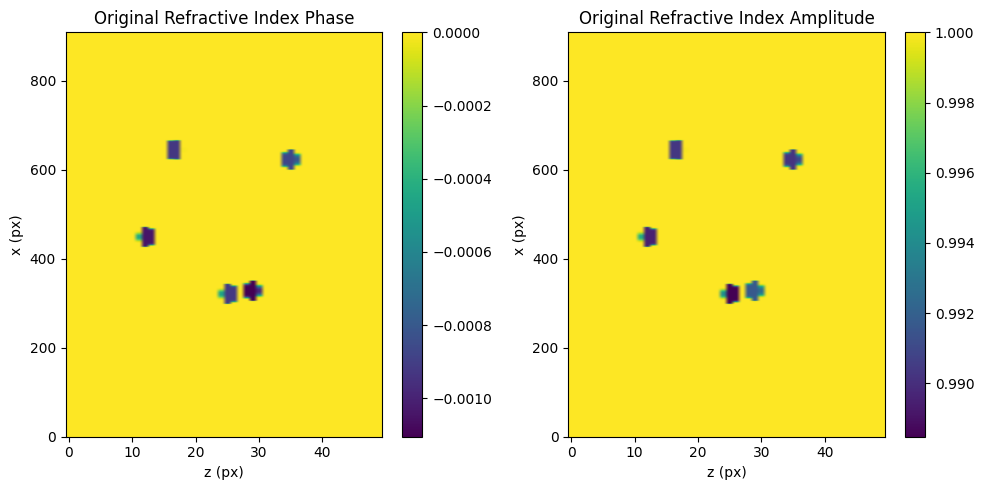

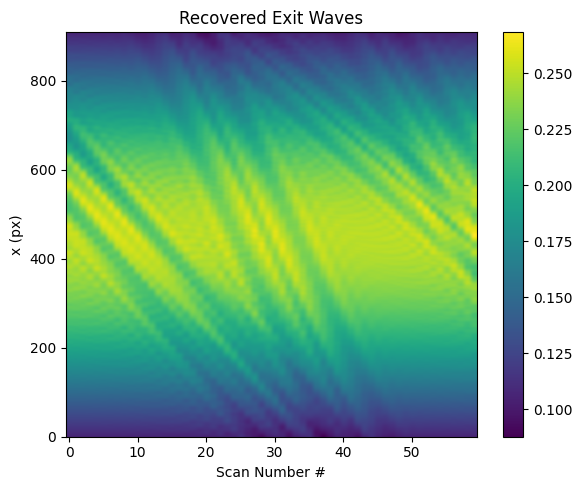

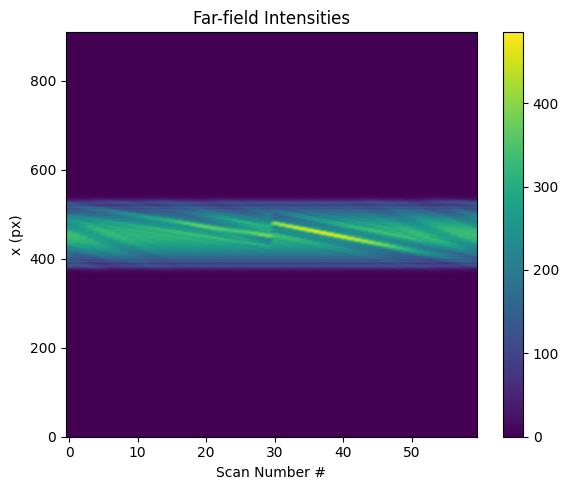

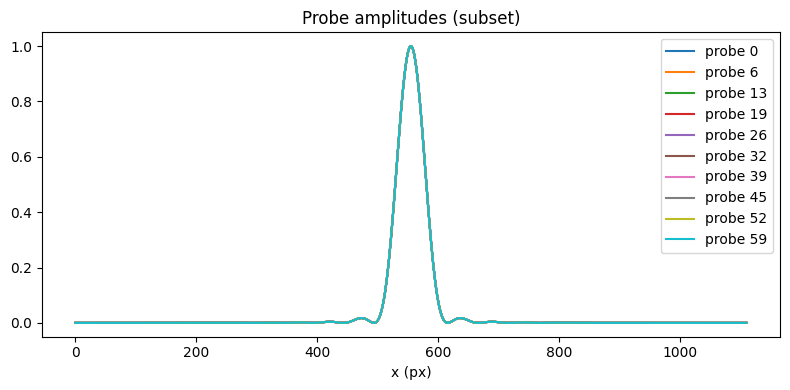

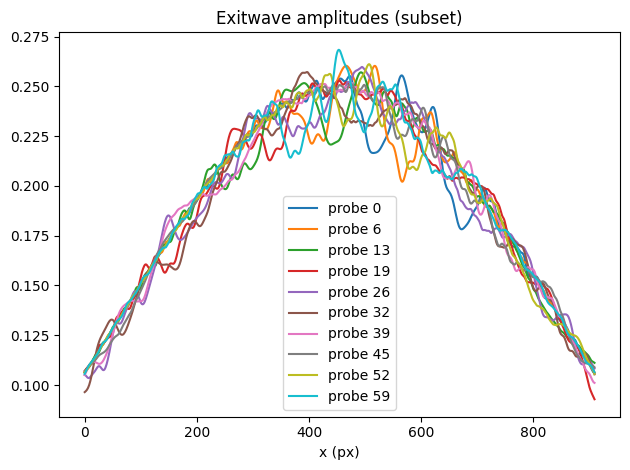

In [12]:
# Original Refactive Index Shap
simulation_space.viewer.plot_two_panels(
    resampled_data["ref_index"],  # Use ifftshift to move zero frequency to the corner
    title="Original Refractive Index",
    xlabel="z (px)",
    ylabel="x (px)",
)
plot_data(
    data=resampled_data["diffraction_clean"],
    exitwaves=resampled_data["exit_waves"],
    simulation_space=simulation_space,
    probes=ptycho_probes,
)

### 4. Reconstructs on Coarser nz Discretization
The exit wave of the forward solution can be set as the initial condition for
the system to be solved in reverse. 

In [13]:
data_type = "clean"  # "noisy", "clean", "exitwaves"


if data_type == "noisy":
    data = resampled_data["diffraction_noisy"]
    phase_retrieval = True
elif data_type == "clean":
    data = resampled_data["diffraction_clean"]
    phase_retrieval = True
elif data_type == "exitwaves":
    data = resampled_data["exit_waves"]
    phase_retrieval = False
else:
    raise ValueError(f"Unknown data_type: {data_type}")

In [14]:
recon_ms = ReconstructorMS(
    simulation_space, data, phase_retrieval=phase_retrieval, verbose=True,
    method="Paraxial", transform='absorbing_boundary',
    pruning_fraction=0.0, strang_splitting=False
)
time_start = time.time()
n_est_ms, residual_ms = recon_ms.reconstruct(max_iters=30, alpha_obj=1e-7)
time_end = time.time()
print(f"Reconstruction time: {time_end - time_start:.2f} seconds")

simulation_space.viewer.plot_two_panels(
    n_est_ms,
    view="phase_amp",
    title="MS Paraxial Absorbing Boundary Reconstruction",
    xlabel="z (px)",
    ylabel="x (px)",
)
simulation_space.viewer.plot_residual(
    residual_ms,
    title="Residuals for MS Paraxial Absorbing Boundary Reconstruction",
)

2026-01-13 18:31:13,261 - INFO - Initialized Multislice 3PIE Reconstructor.


ValueError: operands could not be broadcast together with shapes (910,) (710,) 

2026-01-13 18:09:55,113 - INFO - Initialized Multislice 3PIE Reconstructor.
2026-01-13 18:09:55,578 - INFO - [Iter 001] Mean Loss = 0.597246789252632
2026-01-13 18:09:55,962 - INFO - [Iter 002] Mean Loss = 0.5971472825632825
2026-01-13 18:09:56,362 - INFO - [Iter 003] Mean Loss = 0.5970922413039479
2026-01-13 18:09:56,730 - INFO - [Iter 004] Mean Loss = 0.5970537854894925
2026-01-13 18:09:57,133 - INFO - [Iter 005] Mean Loss = 0.5970241513497053
2026-01-13 18:09:57,579 - INFO - [Iter 006] Mean Loss = 0.5970000217319426
2026-01-13 18:09:57,986 - INFO - [Iter 007] Mean Loss = 0.5969796624875702
2026-01-13 18:09:58,401 - INFO - [Iter 008] Mean Loss = 0.5969620502930726
2026-01-13 18:09:58,796 - INFO - [Iter 009] Mean Loss = 0.5969465298335279
2026-01-13 18:09:59,210 - INFO - [Iter 010] Mean Loss = 0.5969326558405815
2026-01-13 18:09:59,607 - INFO - [Iter 011] Mean Loss = 0.5969201118211774
2026-01-13 18:10:00,008 - INFO - [Iter 012] Mean Loss = 0.5969086646868849
2026-01-13 18:10:00,441 -

Reconstruction time: 13.33 seconds


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Residuals for MS Reconstruction'}, xlabel='Iteration', ylabel='RMSE'>)

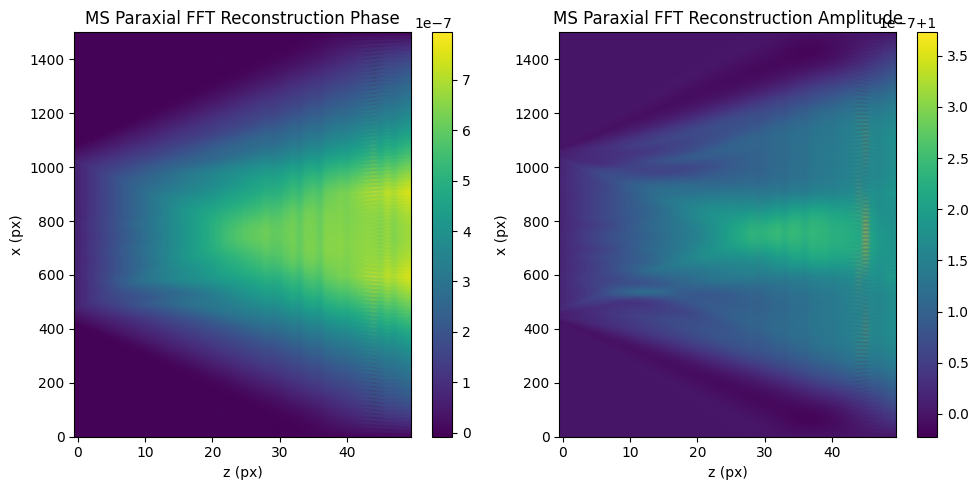

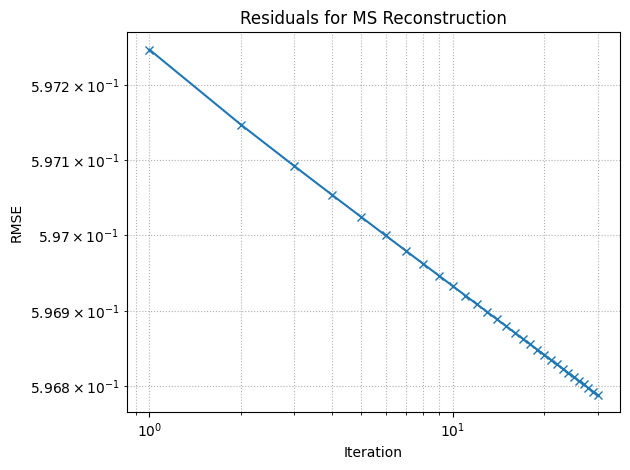

In [ ]:
recon_ms = ReconstructorMS(
    simulation_space, data, phase_retrieval=phase_retrieval, verbose=True,
    method="Paraxial", transform='FFT',
    pruning_fraction=0.0, strang_splitting=False
)
time_start = time.time()
n_est_ms, residual_ms = recon_ms.reconstruct(max_iters=30, alpha_obj=1e-7)
time_end = time.time()
print(f"Reconstruction time: {time_end - time_start:.2f} seconds")

simulation_space.viewer.plot_two_panels(
    n_est_ms,
    view="phase_amp",
    title="MS Paraxial FFT Reconstruction",
    xlabel="z (px)",
    ylabel="x (px)",
)
simulation_space.viewer.plot_residual(
    residual_ms,
    title="Residuals for MS Reconstruction",
)

2026-01-13 18:10:09,744 - INFO - Initialized Multislice 3PIE Reconstructor.
2026-01-13 18:10:10,251 - INFO - [Iter 001] Mean Loss = 0.5972104878615447
2026-01-13 18:10:10,700 - INFO - [Iter 002] Mean Loss = 0.5970518140728002
2026-01-13 18:10:11,117 - INFO - [Iter 003] Mean Loss = 0.5969641791982407
2026-01-13 18:10:11,548 - INFO - [Iter 004] Mean Loss = 0.5969029925695787
2026-01-13 18:10:12,011 - INFO - [Iter 005] Mean Loss = 0.5968558602903304
2026-01-13 18:10:12,521 - INFO - [Iter 006] Mean Loss = 0.5968174925441184
2026-01-13 18:10:13,040 - INFO - [Iter 007] Mean Loss = 0.5967851257984979
2026-01-13 18:10:14,483 - INFO - [Iter 008] Mean Loss = 0.5967571300707066
2026-01-13 18:10:14,988 - INFO - [Iter 009] Mean Loss = 0.5967324619252224
2026-01-13 18:10:15,404 - INFO - [Iter 010] Mean Loss = 0.5967104125715268
2026-01-13 18:10:15,822 - INFO - [Iter 011] Mean Loss = 0.5966904783178032
2026-01-13 18:10:16,246 - INFO - [Iter 012] Mean Loss = 0.5966722882755098
2026-01-13 18:10:16,662 

Reconstruction time: 13.83 seconds


(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Residuals for MS ASM FFT Reconstruction (Pruning 0%)'}, xlabel='Iteration', ylabel='RMSE'>)

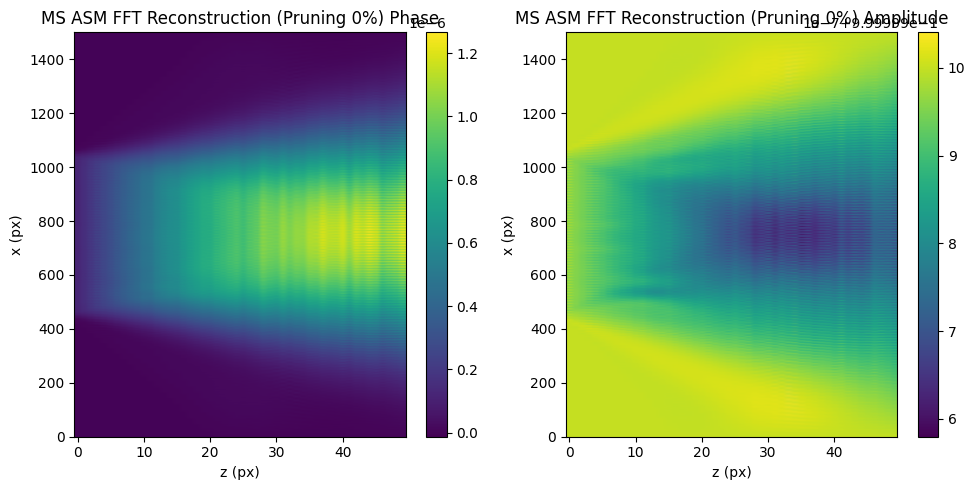

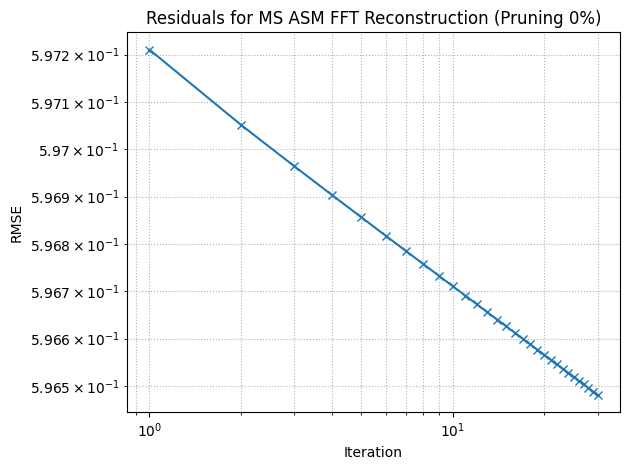

In [ ]:
pruning_fraction = 0.0
recon_ms = ReconstructorMS(
    simulation_space, data, phase_retrieval=phase_retrieval, verbose=True,
    method="ASM", transform='FFT',
    pruning_fraction=pruning_fraction, strang_splitting=False
)
time_start = time.time()
n_est_ms, residual_ms = recon_ms.reconstruct(max_iters=30, alpha_obj=1e-7)
time_end = time.time()
print(f"Reconstruction time: {time_end - time_start:.2f} seconds")

simulation_space.viewer.plot_two_panels(
    n_est_ms,
    view="phase_amp",
    title=f"MS ASM FFT Reconstruction (Pruning {pruning_fraction*100:.0f}%)",
    xlabel="z (px)",
    ylabel="x (px)",
)
simulation_space.viewer.plot_residual(
    residual_ms,
    title=f"Residuals for MS ASM FFT Reconstruction (Pruning {pruning_fraction*100:.0f}%)",
)